# EXP-005 — Random Forest mặc định

**Notebook trình bày và tổng hợp:** [notebooks/experiments/Mai_EXP-005-RF.ipynb](../../../notebooks/experiments/Mai_EXP-005-RF.ipynb)

Người thực hiện:   Mai  
Ngày chạy: 16/11/2026  lần 1  
Lần 2: 18/11/2026  
**So sánh train và test** -22/11/2026    

## Mục tiêu và giả thuyết

Chạy Random Forest (RF) để kiểm tra khả năng nhận diện stress ở người chưa xuất hiện trong dữ liệu train. 
Kỳ vọng RF sẽ cho kết quả Macro-F1 và Balanced Accuracy cao hơn mô hình Dummy nhờ khả năng học từ 68 đặc trưng sinh lý. Dùng kết quả để xem RF có phù hợp với bản demo đọc dữ liệu từ file CSV hay không.

## Dữ liệu và cách đánh giá

Bộ dữ liệu physiological68 gồm 6.189 mẫu, 68 đặc trưng sinh lý và 15 người tham gia. Dùng LOSO. Mỗi lần lấy dữ liệu của 1 người để kiểm tra. Dùng 14 người còn lại để huấn luyện. Quá trình này lặp lại 15 lần.

Thí nghiệm gồm hai bài toán: phân loại Stress và Non-stress. phân loại Baseline, Stress và Amusement.

Dùng Random Forest với tham số mặc định. Tính trung vị từ tập train của từng lần chạy để điền giá trị thiếu. Không chỉnh tham số, cân bằng lớp hay chọn đặc trưng. Thông tin SHA-256 và đường dẫn schema được lưu trong `config.yaml`.

In [1]:
from pathlib import Path
import json

import pandas as pd
import yaml

here = Path.cwd()
repo = next(path for path in (here, *here.parents) if (path / "scripts/run_g3_baselines.py").is_file())
experiment = repo / "experiments/01_baselines/EXP-005_RF"
config = yaml.safe_load((experiment / "config.yaml").read_text(encoding="utf-8"))
output = repo / config["output_dir"]
data = pd.read_csv(repo / config["features"], usecols=["subject_id", "label_original"])
print(f"{len(data)} cửa sổ, {data['subject_id'].nunique()} người")
display(data["label_original"].map({1: "Baseline", 2: "Stress", 3: "Amusement"}).value_counts())


6189 cửa sổ, 15 người


label_original
Baseline     3370
Stress       1848
Amusement     971
Name: count, dtype: int64

## Thiết lập thực nghiệm

Chạy runner G3 với cấu hình `config.yaml`, seed 42 và thư mục kết quả riêng `outputs/exp005_rf_full`. Cả hai bài toán dùng cùng cách chia dữ liệu. Giữ nguyên tham số RF qua các fold.

## Lần 1 — Phân tích kết quả G3

Kết quả RF mặc định đã chạy trước đó nằm trong `results.csv`, gồm 15 người cho mỗi bài toán. Phần nhận xét G3 bên dưới dùng kết quả này để so sánh.

## Kết quả theo người tham gia

Macro-F1 là trung bình F1 của các lớp và Balanced Accuracy là trung bình recall của các lớp. Tính riêng hai chỉ số cho từng người test. Tính trung bình và độ lệch chuẩn mẫu qua 15 người cho mỗi bài toán.

Bảng `results.csv` lưu 30 dòng RF từ `reports/g3_group/metrics_by_subject.csv` (kết quả G3 đã chạy trước đó). Điểm của lần 2 được trình bày ở mục riêng bên dưới.

In [2]:
g3_source = repo / "reports/g3_group/metrics_by_subject.csv"
g3 = pd.read_csv(g3_source)
results = pd.read_csv(experiment / "results.csv")
metrics = ["macro_f1", "balanced_accuracy"]

keys = ["task", "subject_id"]
assert len(results) == 30 and not results.duplicated(keys).any()
assert set(results["model"]) == {"rf"}
assert set(results["task"]) == {"binary", "multiclass"}
assert results.groupby("task")["subject_id"].apply(
    lambda ids: set(ids) == set(config["expected_subjects"])
).all()

print("Trạng thái: historical (phân tích kết quả G3)")
print("Nguồn điểm RF: results.csv")
display(results[keys + metrics].sort_values(keys).round(4))
display(results.groupby("task")[metrics].agg(["mean", "std"]).round(4))


Trạng thái: historical (phân tích kết quả G3)
Nguồn điểm RF: results.csv


,task,subject_id,macro_f1,balanced_accuracy
15,binary,S10,0.5017,0.6409
16,binary,S11,0.9832,0.9897
17,binary,S13,0.6991,0.7884
18,binary,S14,0.9855,0.9802
19,binary,S15,0.6856,0.6667
20,binary,S16,1.0000,1.0000
21,binary,S17,0.9028,0.8840
22,binary,S2,0.9177,0.8947
23,binary,S3,0.9366,0.9153
24,binary,S4,1.0000,1.0000


macro_f1         balanced_accuracy        
               mean     std              mean     std
task                                                 
binary       0.8735  0.1440            0.8865  0.1143
multiclass   0.6480  0.1297            0.6700  0.1204

## Đối chiếu với các mô hình cơ sở

So sánh RF với Dummy, LR, KNN, SVM và MLP trên cùng 15 người. Trình bày riêng hai bài toán. Điểm RF lấy từ nguồn ghi ở phần kết quả. Điểm của năm mô hình đối chiếu lấy từ bảng G3. Dùng Dummy làm mốc để tính chênh lệch theo từng người. Dummy luôn dự đoán lớp phổ biến nhất trong tập train.

macro_f1  balanced_accuracy
task       model                               
binary     Dummy      0.4123             0.5000
           KNN        0.7258             0.7541
           LR         0.8103             0.8304
           MLP        0.7986             0.8225
           RF (G3)    0.8735             0.8865
           SVM        0.8424             0.8663
multiclass Dummy      0.2350             0.3333
           KNN        0.5555             0.5753
           LR         0.5894             0.6315
           MLP        0.6462             0.6815
           RF (G3)    0.6480             0.6700
           SVM        0.6177             0.6595

,macro_f1_rf,macro_f1_dummy,macro_f1_delta,balanced_accuracy_rf,balanced_accuracy_dummy,balanced_accuracy_delta
task,,,,,,
binary,0.8735,0.4123,0.4612,0.8865,0.5000,0.3865
multiclass,0.6480,0.2350,0.4129,0.6700,0.3333,0.3367


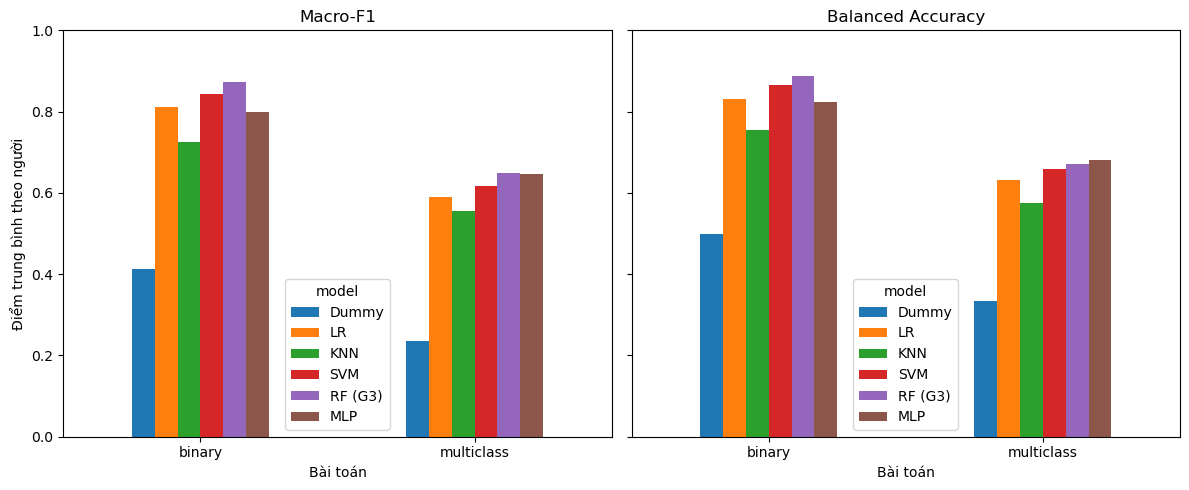

In [3]:
import matplotlib.pyplot as plt

dummy = g3.loc[g3["model"].eq("dummy")]
rf_label = "RF (G3)"
model_labels = {"dummy": "Dummy", "lr": "LR", "knn": "KNN", "svm": "SVM", "rf": rf_label, "mlp": "MLP"}
baseline_rows = pd.concat([g3.loc[g3["model"].ne("rf")], results], ignore_index=True)
model_scores = baseline_rows.groupby(["task", "model"])[metrics].mean()
display(model_scores.rename(index=model_labels, level="model").round(4))
keys = ["task", "subject_id"]
paired = results.merge(dummy[keys + metrics], on=keys, suffixes=("_rf", "_dummy"), validate="one_to_one")
assert len(paired) == 30

for metric in metrics:
    paired[f"{metric}_delta"] = paired[f"{metric}_rf"] - paired[f"{metric}_dummy"]

columns = [f"{metric}_{suffix}" for metric in metrics for suffix in ("rf", "dummy", "delta")]
comparison = paired.groupby("task")[columns].mean()
display(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, metric, title in zip(axes, metrics, ["Macro-F1", "Balanced Accuracy"]):
    scores = model_scores[metric].unstack("model").reindex(columns=list(model_labels))
    scores.rename(columns=model_labels).plot.bar(ax=ax, rot=0, title=title)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Bài toán")
axes[0].set_ylabel("Điểm trung bình theo người")
fig.tight_layout()
figures = experiment / "figures"
figures.mkdir(exist_ok=True)
fig.savefig(figures / "rf_vs_baselines_g3.png", dpi=150)
plt.show()


## Nhận xét và kết luận

Trong kết quả G3 đã chạy trước đó, RF đạt Macro-F1 **0,8735** và Balanced Accuracy **0,8865** ở bài toán nhị phân. Với ba lớp, hai điểm tương ứng là **0,6480** và **0,6700**. RF vượt Dummy trên cả hai chỉ số ở cả hai bài toán.

RF dẫn đầu các mô hình cơ sở G3 ở cả hai chỉ số trong bài toán nhị phân. Với ba lớp, RF có Macro-F1 cao nhất, còn MLP có Balanced Accuracy cao hơn RF (0,6815 so với 0,6700). Dựa vào điểm trung bình, RF là lựa chọn hợp lý để thử làm demo nhị phân trên dữ liệu physiological68. Với ba lớp, cần xem cả chênh lệch giữa các mô hình và mức thay đổi điểm giữa người tham gia. Thí nghiệm này chưa đo độ trễ suy luận.

Dùng kết quả G3 đã chạy trước đó làm mốc so sánh. Cell dưới tính kết quả từ nguồn RF đang phân tích. Cell cũng cho biết số người có Macro-F1 tăng so với Dummy.

In [4]:
from IPython.display import Markdown

task_names = {"binary": "Nhị phân", "multiclass": "Ba lớp"}
source_name = "kết quả lịch sử G3"
lines = [f"**Kết quả từ {source_name}**"]
for task, folds in paired.groupby("task"):
    scores = comparison.loc[task]
    improved = folds["macro_f1_delta"].gt(0).sum()
    weakest = folds.loc[folds["macro_f1_rf"].idxmin()]
    lines.append(
        f"- **{task_names[task]}** — Macro-F1 {scores['macro_f1_rf']:.4f} "
        f"(chênh lệch so với Dummy {scores['macro_f1_delta']:+.4f}), "
        f"Balanced Accuracy {scores['balanced_accuracy_rf']:.4f} "
        f"(chênh lệch {scores['balanced_accuracy_delta']:+.4f}). "
        f"Macro-F1 cao hơn Dummy ở {improved}/{len(folds)} người. "
        f"Fold có Macro-F1 RF thấp nhất là {weakest['subject_id']} "
        f"({weakest['macro_f1_rf']:.4f})."
    )
display(Markdown("\n".join(lines)))


**Kết quả từ kết quả lịch sử G3**
- **Nhị phân** — Macro-F1 0.8735 (chênh lệch so với Dummy +0.4612), Balanced Accuracy 0.8865 (chênh lệch +0.3865). Macro-F1 cao hơn Dummy ở 15/15 người. Fold có Macro-F1 RF thấp nhất là S10 (0.5017).
- **Ba lớp** — Macro-F1 0.6480 (chênh lệch so với Dummy +0.4129), Balanced Accuracy 0.6700 (chênh lệch +0.3367). Macro-F1 cao hơn Dummy ở 15/15 người. Fold có Macro-F1 RF thấp nhất là S10 (0.3649).

## Lần 2 — Kiểm tra chạy lại và đối chiếu kết quả

Dùng cùng cấu hình và cách chia LOSO như G3. Runner dùng thư mục riêng `outputs/exp005_rf_full/` và có thể tiếp tục từ các fold hợp lệ đã lưu. So sánh Macro-F1 và Balanced Accuracy với G3 theo từng bài toán và người test.

**Hai chỉ số khớp kết quả G3 ở đủ 30 fold.**

In [5]:
import subprocess

command = [
    str(repo / ".venv-g1/Scripts/python.exe"),
    "-X", "utf8", "scripts/run_g3_baselines.py",
    "--config", str(experiment / "config.yaml"),
    "--resume",
]
print((experiment / "config.yaml").read_text(encoding="utf-8"))

RUN_BASELINE = False
if RUN_BASELINE:
    subprocess.run(command, cwd=repo, check=True)


protocol: g3_defaults_physiological68_v1
features: data/features/g2_physiological68_group15_20261107/all_subjects.csv
schema: data/features/g2_physiological68_group15_20261107/feature_schema.json
feature_version: physiological_68_v1
feature_sha256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
output_dir: outputs/exp005_rf_full
source_paths:
- src/wesad/data.py
- src/wesad/evaluation.py
- src/wesad/models.py
- src/wesad/utils.py
- src/wesad/g3.py
- scripts/run_g3_baselines.py
- scripts/merge_g3_predictions.py
source_hash_normalization: LF
expected_subjects:
- S2
- S3
- S4
- S5
- S6
- S7
- S8
- S9
- S10
- S11
- S13
- S14
- S15
- S16
- S17
models:
- rf
tasks:
- multiclass
- binary
seed: 42
sensor_set: combined_physiological68
normalization: global_train
balance: false
nested: false
zero_division: 0
missing_train_class: error
missing_test_class: fixed_labels_for_macro_f1_observed_classes_for_balanced_accuracy
model_params:
  rf:
    random_state: 42
    n_jobs: 1



In [6]:
import numpy as np

verification = json.loads((output / "verification.json").read_text(encoding="utf-8"))
assert verification["status"] == "passed" and verification["scope"] == "main"
assert verification["models"] == ["rf"] and verification["n_folds"] == 30
assert verification["n_predictions"] == 12378
assert verification["data_sha256"] == config["feature_sha256"]

rerun_results = pd.read_csv(output / "verified_metrics_by_subject.csv")
assert len(rerun_results) == len(results)
assert set(rerun_results["model"]) == {"rf"}
matched = results[keys + metrics].merge(
    rerun_results[keys + metrics], on=keys, suffixes=("_g3", "_rerun"),
    validate="one_to_one",
)
assert len(matched) == len(results) == 30

print("Trạng thái: rerun (đã xác minh 30 fold)")
display(rerun_results.groupby("task")[metrics].agg(["mean", "std"]).round(4))

for metric in metrics:
    matched[f"{metric}_delta"] = matched[f"{metric}_rerun"] - matched[f"{metric}_g3"]

from IPython.display import Markdown

display(Markdown("### Đối chiếu Lần 1 và Lần 2"))

summary_columns = [
    f"{metric}_{suffix}"
    for metric in metrics
    for suffix in ("g3", "rerun", "delta")
]
comparison_summary = matched.groupby("task")[summary_columns].mean()
comparison_summary.columns = pd.MultiIndex.from_product([
    ["Macro-F1", "Balanced Accuracy"],
    ["Lần 1 (G3)", "Lần 2", "Chênh lệch"],
])
display(comparison_summary.rename(index={"binary": "Nhị phân", "multiclass": "Ba lớp"}).round(4))

delta_columns = [f"{metric}_delta" for metric in metrics]
different = ~np.isclose(matched[delta_columns], 0, atol=1e-10, rtol=0).all(axis=1)
if different.any():
    print(f"Số fold có điểm khác G3: {different.sum()}/30")
    display(matched.loc[different, keys + delta_columns])
else:
    print("Hai metric khớp kết quả G3 ở đủ 30 fold.")

rerun_file = experiment / "results_rerun.csv"
if not rerun_file.exists():
    rerun_results.to_csv(rerun_file, index=False, mode="x")
    print("Bảng kết quả:", rerun_file.name)
elif pd.read_csv(rerun_file).equals(rerun_results):
    print("Đã có bảng kết quả:", rerun_file.name)
else:
    print("Bảng CSV của lượt này:", output / "verified_metrics_by_subject.csv")

Trạng thái: rerun (đã xác minh 30 fold)


macro_f1         balanced_accuracy        
               mean     std              mean     std
task                                                 
binary       0.8735  0.1440            0.8865  0.1143
multiclass   0.6480  0.1297            0.6700  0.1204

### Đối chiếu Lần 1 và Lần 2

Macro-F1                    Balanced Accuracy                   
         Lần 1 (G3)   Lần 2 Chênh lệch        Lần 1 (G3)   Lần 2 Chênh lệch
task                                                                       
Nhị phân     0.8735  0.8735        0.0            0.8865  0.8865        0.0
Ba lớp       0.6480  0.6480        0.0            0.6700  0.6700        0.0

Hai metric khớp kết quả G3 ở đủ 30 fold.
Đã có bảng kết quả: results_rerun.csv


## So sánh train và test-22/11/2026

Tính điểm theo từng người trong LOSO. Trình bày riêng nhị phân và ba lớp. Thanh sai số là SD giữa 15 fold, không phải khoảng tin cậy.

Fit lại mỗi fold với đúng cấu hình đã dùng để tính thêm điểm train. Kiểm tra dự đoán test có khớp kết quả cũ trước khi lưu. Điểm train là điểm trên dữ liệu đã học, không phải điểm validation.


train_macro_f1      test_macro_f1         gap_macro_f1  \
                              mean  std          mean     std         mean   
task       variant                                                           
binary     baseline            1.0  0.0        0.8735  0.1440       0.1265   
multiclass baseline            1.0  0.0        0.6480  0.1297       0.3520   

                            train_balanced_accuracy       \
                        std                    mean  std   
task       variant                                         
binary     baseline  0.1440                     1.0  0.0   
multiclass baseline  0.1297                     1.0  0.0   

                    test_balanced_accuracy         gap_balanced_accuracy  \
                                      mean     std                  mean   
task       variant                                                         
binary     baseline                 0.8865  0.1143                0.1135   
multiclass baseline                 0.6700  0.1204                0.3300   

                             
                        std  
task       variant           
binary     baseline  0.1143  
multiclass baseline  0.1204

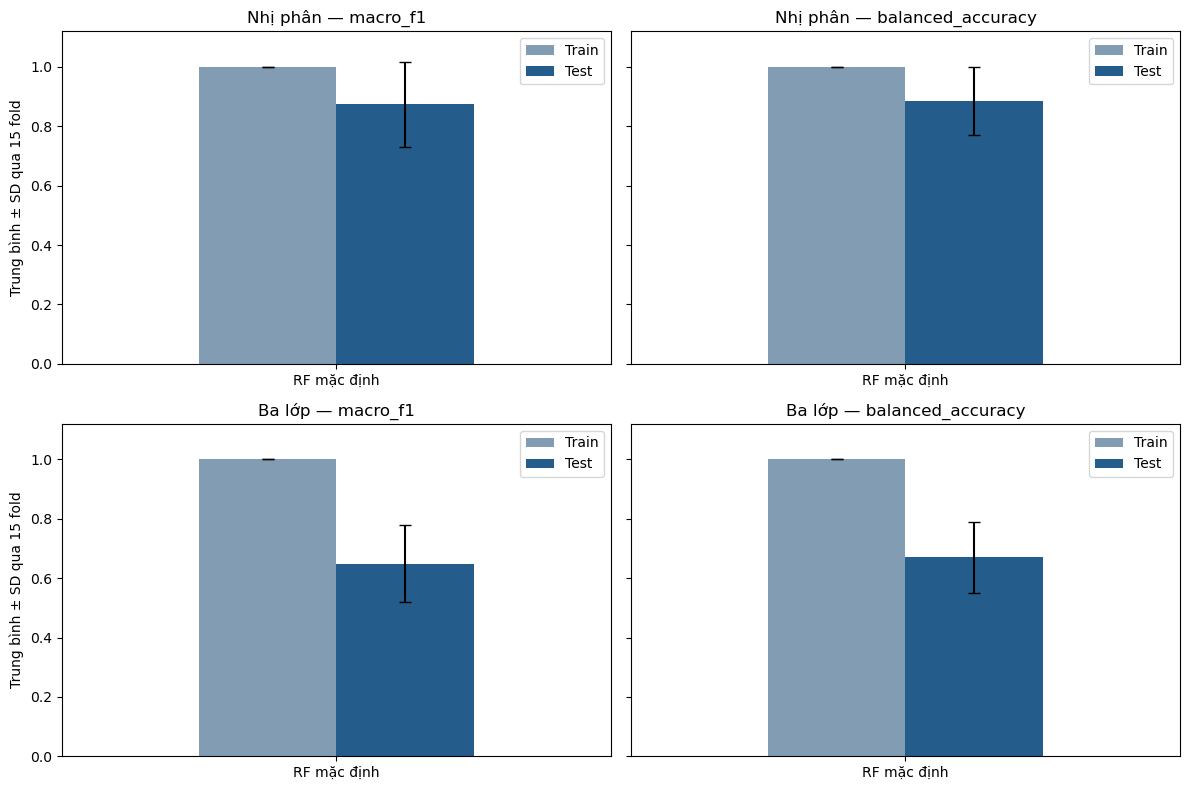

### Nhận xét train–test

- Nhị phân, RF mặc định: train Macro-F1 1.0000; test Macro-F1 0.8735; khoảng cách 0.1265. Train BA 1.0000; test BA 0.8865.

- Ba lớp, RF mặc định: train Macro-F1 1.0000; test Macro-F1 0.6480; khoảng cách 0.3520. Train BA 1.0000; test BA 0.6700.

Khoảng cách train–test mô tả mức chênh lệch giữa dữ liệu đã học và người giữ riêng. Khoảng cách lớn gợi ý cần xem xét overfitting và khác biệt giữa người; chưa đủ để xác định một nguyên nhân duy nhất. Đánh giá hiệu quả dựa trên cả điểm test và độ phân tán theo người.

In [ ]:
from pathlib import Path
import json
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RUN_TRAIN_TEST = False

here_tt = Path.cwd()
repo_tt = next(p for p in (here_tt, *here_tt.parents) if (p / 'src/wesad/evaluation.py').is_file())
package_tt = repo_tt / 'experiments/01_baselines/EXP-005_RF'
source_tt = repo_tt / 'outputs/exp005_rf_full'

if RUN_TRAIN_TEST:
    subprocess.run([
        str(repo_tt / '.venv-g1/Scripts/python.exe'), '-X', 'utf8',
        str(repo_tt / 'scripts/measure_rf_train_test.py'),
        '--source', str(source_tt), '--destination', str(package_tt),
    ], cwd=repo_tt, check=True)
    proof_tt = json.loads((package_tt / 'train_test_verification.json').read_text(encoding='utf-8'))
    assert proof_tt['status'] == 'passed' and proof_tt['n_folds'] == 30
    assert proof_tt['matched_test_predictions'] == 12378
    scores_tt = pd.read_csv(package_tt / 'train_test_metrics.csv')
    assert len(scores_tt) == 30
    assert not scores_tt.duplicated(['task', 'subject_id', 'variant']).any()
    assert set(scores_tt.task) == {'binary', 'multiclass'}
    assert all(len(g) == 15 and g.subject_id.nunique() == 15
               for _, g in scores_tt.groupby(['task', 'variant']))
    for metric in ['macro_f1', 'balanced_accuracy']:
        scores_tt[f'gap_{metric}'] = scores_tt[f'train_{metric}'] - scores_tt[f'test_{metric}']
    columns_tt = [f'{split}_{metric}' for metric in ['macro_f1', 'balanced_accuracy']
                  for split in ['train', 'test', 'gap']]
    assert scores_tt[columns_tt].notna().all().all()
    assert scores_tt[[c for c in columns_tt if not c.startswith('gap_')]].apply(
        lambda col: col.between(0, 1).all()).all()
    summary_tt = scores_tt.groupby(['task', 'variant'])[columns_tt].agg(['mean', 'std'])
    display(summary_tt.round(4))
    summary_tt.to_csv(package_tt / 'train_test_summary.csv')

    names_tt = {'binary': 'Nhị phân', 'multiclass': 'Ba lớp'}
    labels_tt = {'baseline': 'RF mặc định', 'balanced': 'RF cân bằng lớp',
                 'full68': 'Đủ 68 đặc trưng', 'selected': 'Chọn đặc trưng'}
    fig_tt, axes_tt = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
    for row, task in enumerate(['binary', 'multiclass']):
        part_tt = scores_tt.loc[scores_tt.task.eq(task)]
        for col, metric in enumerate(['macro_f1', 'balanced_accuracy']):
            fields_tt = [f'train_{metric}', f'test_{metric}']
            means_tt = part_tt.groupby('variant')[fields_tt].mean()
            errors_tt = part_tt.groupby('variant')[fields_tt].std(ddof=1)
            means_tt = means_tt.rename(index=labels_tt, columns={fields_tt[0]: 'Train', fields_tt[1]: 'Test'})
            errors_tt = errors_tt.rename(index=labels_tt, columns={fields_tt[0]: 'Train', fields_tt[1]: 'Test'})
            means_tt.plot.bar(yerr=errors_tt, ax=axes_tt[row, col], rot=0, capsize=4,
                              color=['#829CB3', '#245C8C'])
            axes_tt[row, col].set_title(f'{names_tt[task]} — {metric}')
            axes_tt[row, col].set_ylim(0, 1.12)
            axes_tt[row, col].set_xlabel('')
            axes_tt[row, col].set_ylabel('Trung bình ± SD qua 15 fold')
    fig_tt.tight_layout()
    (package_tt / 'figures').mkdir(exist_ok=True)
    fig_tt.savefig(package_tt / 'figures/train_vs_test.png', dpi=150, bbox_inches='tight')
    plt.show()

    notes_tt = ['### Nhận xét train–test']
    for (task, variant), group_tt in scores_tt.groupby(['task', 'variant']):
        notes_tt.append(
            f'- {names_tt[task]}, {labels_tt[variant]}: train Macro-F1 '
            f'{group_tt.train_macro_f1.mean():.4f}; test Macro-F1 '
            f'{group_tt.test_macro_f1.mean():.4f}; khoảng cách '
            f'{group_tt.gap_macro_f1.mean():.4f}. Train BA '
            f'{group_tt.train_balanced_accuracy.mean():.4f}; test BA '
            f'{group_tt.test_balanced_accuracy.mean():.4f}.'
        )
    notes_tt.append('Khoảng cách train–test mô tả mức chênh lệch giữa dữ liệu đã học và người giữ riêng. '
                    'Khoảng cách lớn gợi ý cần xem xét overfitting và khác biệt giữa người; '
                    'chưa đủ để xác định một nguyên nhân duy nhất. '
                    'Đánh giá hiệu quả dựa trên cả điểm test và độ phân tán theo người.')
    display(Markdown('\n\n'.join(notes_tt)))
